Regressione lineare

In [ ]:
import polars as pl
from plotnine import *
import statsmodels.formula.api as smf #nuovo per la regressione

In [ ]:
import polars as pl
adv = pl.read_csv("https://www.vincnardelli.com/msd/dati/advertising.csv")

In [ ]:
adv

TV,radio,newspaper,sales
f64,f64,f64,f64
230.1,37.8,69.2,22.1
44.5,39.3,45.1,10.4
17.2,45.9,69.3,9.3
151.5,41.3,58.5,18.5
180.8,10.8,58.4,12.9
…,…,…,…
38.2,3.7,13.8,7.6
94.2,4.9,8.1,9.7
177.0,9.3,6.4,12.8


In [ ]:
adv.columns

['TV', 'radio', 'newspaper', 'sales']

In [ ]:
adv.head(10)

TV,radio,newspaper,sales
f64,f64,f64,f64
230.1,37.8,69.2,22.1
44.5,39.3,45.1,10.4
17.2,45.9,69.3,9.3
151.5,41.3,58.5,18.5
180.8,10.8,58.4,12.9
8.7,48.9,75.0,7.2
57.5,32.8,23.5,11.8
120.2,19.6,11.6,13.2
8.6,2.1,1.0,4.8


In [ ]:
adv.filter(pl.col("TV")>250)

TV,radio,newspaper,sales
f64,f64,f64,f64
281.4,39.6,55.8,24.4
262.9,3.5,19.5,12.0
292.9,28.3,43.2,21.4
265.6,20.0,0.3,17.4
290.7,4.1,8.5,12.8
…,…,…,…
276.7,2.3,23.7,11.8
287.6,43.0,71.8,26.2
253.8,21.3,30.0,17.6


In [ ]:
adv.select("TV","sales").describe()

statistic,TV,sales
str,f64,f64
"""count""",200.0,200.0
"""null_count""",0.0,0.0
"""mean""",147.0425,14.0225
"""std""",85.854236,5.217457
"""min""",0.7,1.6
"""25%""",74.7,10.4
"""50%""",149.8,12.9
"""75%""",218.5,17.4
"""max""",296.4,27.0


/usr/local/lib/python3.13/dist-packages/plotnine/stats/stat_bin.py:109: PlotnineWarning: 'stat_bin()' using 'bins = 11'. Pick better value with 'binwidth'.


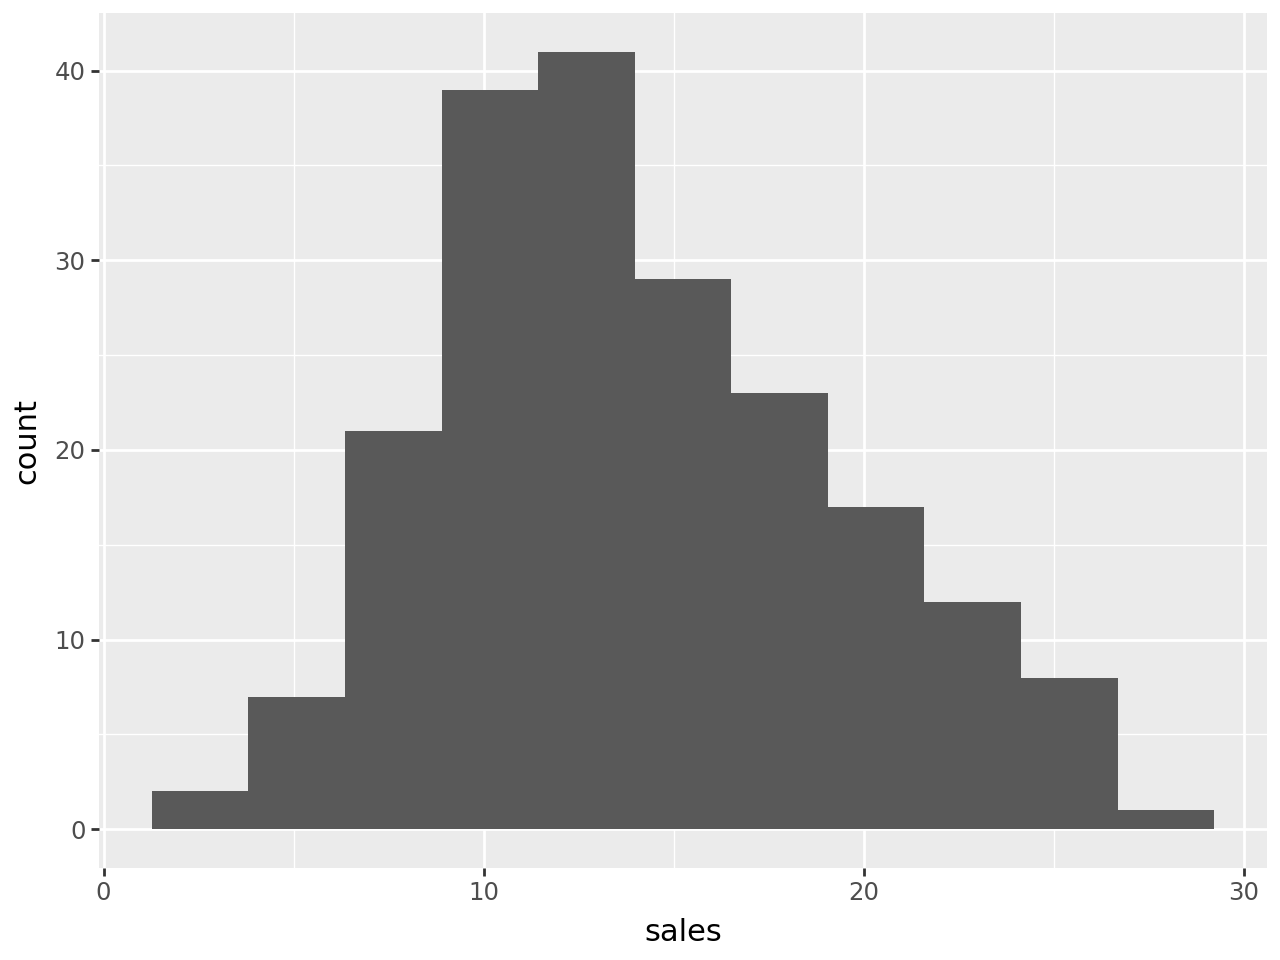

In [ ]:
ggplot(adv, aes(x="sales"))+geom_histogram()

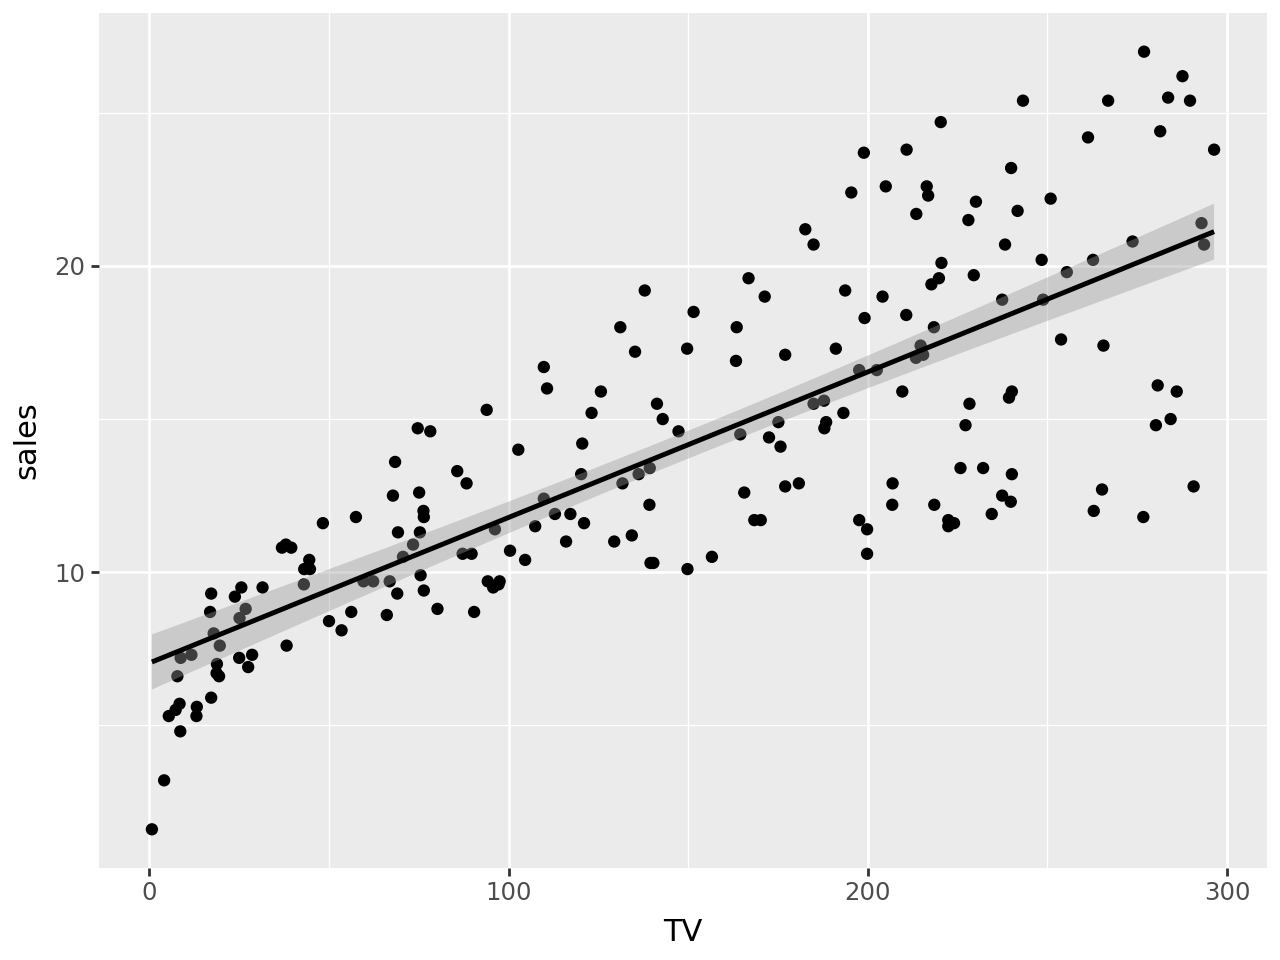

In [ ]:
ggplot(adv, aes(x="TV", y="sales"))+geom_point()+geom_smooth(method="lm")

In [ ]:
# Regressione Semplice:
# Analizza solo l'impatto della TV sulle vendite.
# Ottiene un R-squared di ~0.61 (la TV da sola spiega il 61% della variabilità delle vendite).
# Il coefficiente di TV è significativo (~0.047) con p-value estremamente basso.
modello=smf.ols("sales~TV", data=adv).fit()

In [ ]:
modello.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  sales   R-squared:                       0.612
Model:                            OLS   Adj. R-squared:                  0.610
Method:                 Least Squares   F-statistic:                     312.1
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           1.47e-42
Time:                        09:12:45   Log-Likelihood:                -519.05
No. Observations:                 200   AIC:                             1042.
Df Residuals:                     198   BIC:                             1049.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      7.0326      0.458     15.360      0.000       6.130       7.935
TV             0.0475      0.003     17.668      0.000       0.042       0.053
==============================================================================
Omnibus:                        0.531   Durbin-Watson:                   1.935
Prob(Omnibus):                  0.767   Jarque-Bera (JB):                0.669
Skew:                          -0.089   Prob(JB):                        0.716
Kurtosis:                       2.779   Cond. No.                         338.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
modello.params

,0
Intercept,7.032594
TV,0.047537


In [ ]:
modello.rsquared

np.float64(0.611875050850071)

In [ ]:
modello.pvalues

,0
Intercept,1.406300e-35
TV,1.467390e-42


In [ ]:
multiplo_1 = smf.ols("sales~TV+radio", data=adv).fit()

In [ ]:
# Risultati del Modello Multiplo 1 (TV + radio):
# - R-squared è pari a 0.897, indicando che la combinazione di TV e radio spiega circa il 90% della variabilità delle vendite.
# - Entrambi i coefficienti (TV: ~0.046, radio: ~0.188) hanno un p-value pari a 0.000, dimostrando di essere statisticamente molto significativi.
# - Il coefficiente della radio indica l'incremento delle vendite stimato per ogni unità in più di budget radio, a parità di investimenti in TV.
multiplo_1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     859.6
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           4.83e-98
Time:                        09:12:45   Log-Likelihood:                -386.20
No. Observations:                 200   AIC:                             778.4
Df Residuals:                     197   BIC:                             788.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9211      0.294      9.919      0.000       2.340       3.502
TV             0.0458      0.001     32.909      0.000       0.043       0.048
radio          0.1880      0.008     23.382      0.000       0.172       0.204
==============================================================================
Omnibus:                       60.022   Durbin-Watson:                   2.081
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              148.679
Skew:                          -1.323   Prob(JB):                     5.19e-33
Kurtosis:                       6.292   Cond. No.                         425.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
multiplo_2 = smf.ols("sales~TV+radio+newspaper", data=adv).fit()

In [ ]:
# Analisi di multiplo_2 (Modello completo con TV, radio e newspaper):
# - R-squared è 0.897, lo stesso del modello senza 'newspaper'.
# - Il coefficiente di 'newspaper' è -0.001 con un p-value altissimo (0.860).
# - Questo p-value > 0.05 indica che 'newspaper' non ha un impatto statisticamente significativo sulle vendite quando controllato per TV e radio.
multiplo_2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  sales   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.896
Method:                 Least Squares   F-statistic:                     570.3
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           1.58e-96
Time:                        09:12:45   Log-Likelihood:                -386.18
No. Observations:                 200   AIC:                             780.4
Df Residuals:                     196   BIC:                             793.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9389      0.312      9.422      0.000       2.324       3.554
TV             0.0458      0.001     32.809      0.000       0.043       0.049
radio          0.1885      0.009     21.893      0.000       0.172       0.206
newspaper     -0.0010      0.006     -0.177      0.860      -0.013       0.011
==============================================================================
Omnibus:                       60.414   Durbin-Watson:                   2.084
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              151.241
Skew:                          -1.327   Prob(JB):                     1.44e-33
Kurtosis:                       6.332   Cond. No.                         454.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
# Confronto tra multiplo_1 (TV + radio) e multiplo_2 (TV + radio + newspaper):
# 1. R-squared rimane identico (0.897) in entrambi i modelli, indicando che l'aggiunta di 'newspaper' non migliora la spiegazione delle vendite.
# 2. Il p-value di 'newspaper' in multiplo_2 è molto alto (0.860), ben oltre la soglia classica di 0.05. Questo dimostra che non è statisticamente significativo.
# 3. Di conseguenza, escludiamo 'newspaper' per mantenere il modello più semplice ed efficiente.
